<a href="https://colab.research.google.com/github/diloo11/MachineLearning/blob/main/JS10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Lab 1

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

Saving Iris (1).csv to Iris (1) (2).csv


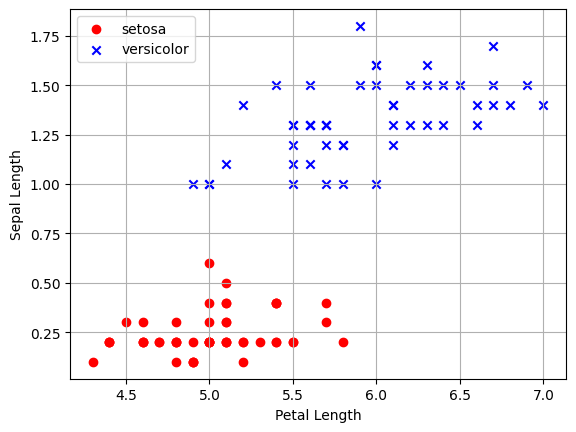

In [4]:
from google.colab import files
uploaded = files.upload()

df = pd.read_csv('Iris (1).csv')

setosa = df[df['Species'] == 'Iris-setosa']
versicolor = df[df['Species'] == 'Iris-versicolor']
virginica = df[df['Species'] == 'Iris-virginica']

a, b = 1, 4

plt.scatter(setosa.iloc[:, a], setosa.iloc[:, b], color='red', marker='o', label='setosa')
plt.scatter(versicolor.iloc[:, a], versicolor.iloc[:, b], color='blue', marker='x', label='versicolor')

plt.xlabel('Petal Length')
plt.ylabel('Sepal Length')
plt.legend(loc='upper left')
plt.grid()
plt.show()

In [5]:
class Perceptron(object):
    def __init__(self, eta=0.01, n_iter=10):
        self.eta = eta
        self.n_iter = n_iter

    def fit(self, X, y):

        self.w_ = np.zeros(1 + X.shape[1])
        self.errors_ = []

        for _ in range(self.n_iter):
            errors = 0
            for xi, target in zip(X, y):
                update = self.eta * (target - self.predict(xi))
                self.w_[0] += update
                self.w_[1:] += update * xi
                errors += int(update != 0.0)
            self.errors_.append(errors)
        return self

    def net_input(self, X):
        return np.dot(X, self.w_[1:]) + self.w_[0]

    def predict(self, X):
        return np.where(self.net_input(X) >= 0.0, 1, -1)

In [6]:
y = df.iloc[0:100]['Species'].values
y = np.where(y == 'Iris-setosa', -1, 1)
X = df.iloc[0:100][['SepalLengthCm', 'PetalWidthCm']].values

In [7]:
ppn = Perceptron(eta=0.1, n_iter=10)
ppn.fit(X, y)

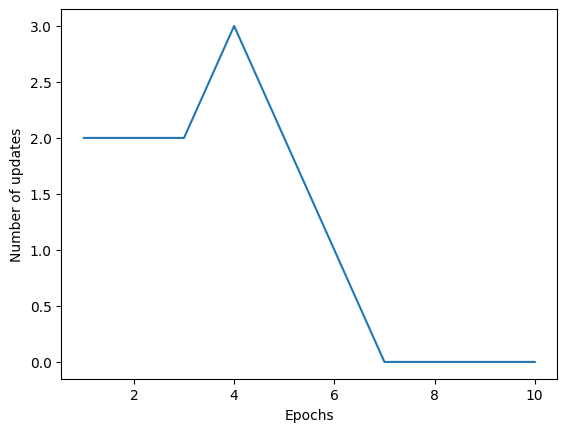

In [8]:
plt.plot(range(1, len(ppn.errors_)+1), ppn.errors_)
plt.xlabel('Epochs')
plt.ylabel('Number of updates')
plt.show()

/tmp/ipykernel_418/1725434117.py:27: UserWarning: *c* argument looks like a single numeric RGB or RGBA sequence, which should be avoided as value-mapping will have precedence in case its length matches with *x* & *y*.  Please use the *color* keyword-argument or provide a 2D array with a single row if you intend to specify the same RGB or RGBA value for all points.
  plt.scatter(x=X[y==cl, 0], y=X[y==cl, 1], alpha=0.8, c=cmap(i), marker=markers[i], label=cl)


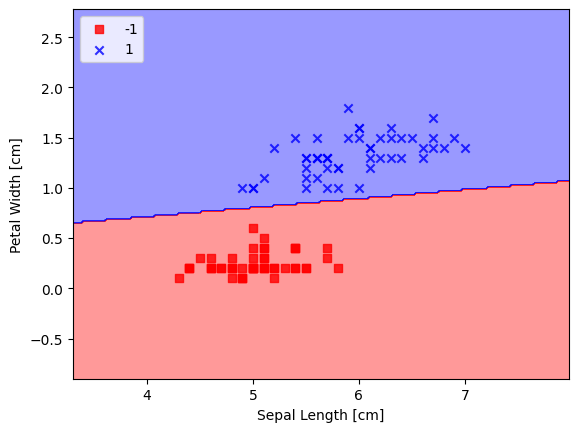

In [9]:
# create a function to plot the decision regions

from matplotlib.colors import ListedColormap

def plot_decision_regions(X, y, classifier, resolution=0.02):
    # setup marker generator and color map
    markers = ('s', 'x', 'o', '^', 'v')
    colors = ('r', 'b', 'g', 'k', 'grey')
    cmap = ListedColormap(colors[:len(np.unique(y))])

    # plot the decision regions by creating a pair of grid arrays xx1 and xx2 via meshgrid function in Numpy
    x1_min, x1_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    x2_min, x2_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx1, xx2 = np.meshgrid(np.arange(x1_min, x1_max, resolution), np.arange(x2_min, x2_max, resolution))

    # use predict method to predict the class labels z of the grid points
    Z = classifier.predict(np.array([xx1.ravel(),xx2.ravel()]).T)
    Z = Z.reshape(xx1.shape)

    # draw the contour using matplotlib
    plt.contourf(xx1, xx2, Z, alpha=0.4, cmap=cmap)
    plt.xlim(xx1.min(), xx1.max())
    plt.ylim(xx2.min(), xx2.max())

    # plot class samples
    for i, cl in enumerate(np.unique(y)):
        plt.scatter(x=X[y==cl, 0], y=X[y==cl, 1], alpha=0.8, c=cmap(i), marker=markers[i], label=cl)

plot_decision_regions(X, y, classifier=ppn)

plt.xlabel('Sepal Length [cm]')
plt.ylabel('Petal Width [cm]')
plt.legend(loc='upper left')
plt.show()

Lab 2

In [10]:
from sklearn.neural_network import MLPClassifier

In [11]:
y = [0, 1, 1, 0] # labels
X = [[0, 0], [0, 1], [1, 0], [1, 1]] # data

In [12]:
# Fit model
clf = MLPClassifier(solver='lbfgs', activation='logistic', hidden_layer_sizes=(2,), max_iter=100, random_state=20)
clf.fit(X, y)

MLPClassifier(activation='logistic', hidden_layer_sizes=(2,), max_iter=100,
              random_state=20, solver='lbfgs')

In [13]:
pred = clf.predict(X)
print('Accuracy: %s' % clf.score(X, y))
for i,p in enumerate(pred[:10]):
    print('True: %s, Predicted: %s' % (y[i], p))

Accuracy: 1.0
True: 0, Predicted: 0
True: 1, Predicted: 1
True: 1, Predicted: 1
True: 0, Predicted: 0


Lab 3

In [14]:
import numpy as np
import pandas as pd
import tensorflow as tf

In [16]:
from google.colab import files
uploaded = files.upload()
dataset = pd.read_csv('Churn_Modelling.csv')
X = dataset.iloc[:, 3:-1].values
y = dataset.iloc[:, -1].values

Saving Churn_Modelling.csv to Churn_Modelling.csv


In [17]:
print(X)

[[619 'France' 'Female' ... 1 1 101348.88]
 [608 'Spain' 'Female' ... 0 1 112542.58]
 [502 'France' 'Female' ... 1 0 113931.57]
 ...
 [709 'France' 'Female' ... 0 1 42085.58]
 [772 'Germany' 'Male' ... 1 0 92888.52]
 [792 'France' 'Female' ... 1 0 38190.78]]


In [18]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
X[:, 2] = le.fit_transform(X[:, 2])

In [19]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
ct = ColumnTransformer(transformers=[('encoder', OneHotEncoder(), [1])], remainder='passthrough')
X = np.array(ct.fit_transform(X))

In [21]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 0)

In [22]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

In [23]:
ann = tf.keras.models.Sequential()

In [54]:
ann.add(tf.keras.layers.Dense(units=6, activation='relu'))

In [55]:
ann.add(tf.keras.layers.Dense(units=6, activation='relu'))

In [56]:
ann.add(tf.keras.layers.Dense(units=1, activation='sigmoid'))

In [26]:
ann.compile(optimizer = 'adam', loss = 'binary_crossentropy', metrics = ['accuracy'])

In [27]:
ann.fit(X_train, y_train, batch_size = 32, epochs = 100)

Epoch 1/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.5410 - loss: 0.7617
Epoch 2/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7764 - loss: 0.5330
Epoch 3/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8027 - loss: 0.4684
Epoch 4/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8054 - loss: 0.4434
Epoch 5/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8062 - loss: 0.4307
Epoch 6/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8092 - loss: 0.4218
Epoch 7/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8135 - loss: 0.4138
Epoch 8/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8181 - loss: 0.4055
Epoch 9/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8241 - loss: 0.3968
Epoch 10/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8321 - loss: 0.3889
Epoch 11/100
250/250 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.8376 - loss: 0.3817
Epoch 12/100
250/250 ━━━━━━━━━━━━━━━━━━━━

In [28]:
print(ann.predict(sc.transform([[1, 0, 0, 600, 1, 40, 3, 60000, 2, 1, 1, 50000]])) > 0.5)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
[[False]]


In [29]:
y_pred = ann.predict(X_test)
y_pred = (y_pred > 0.5)
print(np.concatenate((y_pred.reshape(len(y_pred),1), y_test.reshape(len(y_test),1)),1))

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
[[0 0]
 [0 1]
 [0 0]
 ...
 [0 0]
 [0 0]
 [0 0]]


In [30]:
from sklearn.metrics import confusion_matrix, accuracy_score
cm = confusion_matrix(y_test, y_pred)
print(cm)
accuracy_score(y_test, y_pred)

[[1513   82]
 [ 199  206]]


0.8595

Lab 4

In [80]:
from google.colab import files

uploaded = files.upload()

Saving images.zip to images (1).zip


In [81]:
import zipfile

with zipfile.ZipFile('/content/images.zip', 'r') as zip_ref:
    zip_ref.extractall('/content/')

In [82]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import cv2

from skimage.feature import hog
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report

import tensorflow as tf
from tensorflow.keras import layers, models

In [83]:
def load_dataset(img_dir):
    p = Path(img_dir)
    img_list = []

    if not p.exists():
        raise FileNotFoundError(f"Directory not found: {p}")

    for folder in p.iterdir():
        if not folder.is_dir():
            continue

        label = folder.name.lower()

        if label not in ['day', 'night']:
            continue

        for file in folder.iterdir():
            if file.suffix.lower() not in ['.jpg', '.jpeg', '.png']:
                continue

            img = cv2.imread(str(file))

            if img is None:
                continue

            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img_list.append((img, label))

    return img_list


train_dir = "/content/images/training/"
test_dir = "/content/images/test/"

train_img = load_dataset(train_dir)
test_img = load_dataset(test_dir)

print("Training images:", len(train_img))
print("Testing images:", len(test_img))

Training images: 240
Testing images: 160


In [84]:
def resize_image(img, size=(256, 256)):
    return cv2.resize(img, size)


def label_encoder(label):
    return 1 if label == 'day' else 0


def preprocess(img_list):
    X = []
    y = []

    for img, label in img_list:
        img_std = resize_image(img)

        X.append(img_std)
        y.append(label_encoder(label))

    return np.array(X), np.array(y)


X_train_img, y_train = preprocess(train_img)
X_test_img, y_test = preprocess(test_img)

print("Training images shape:", X_train_img.shape)
print("Testing images shape:", X_test_img.shape)

print("Training labels:", y_train.shape)
print("Testing labels:", y_test.shape)

Training images shape: (240, 256, 256, 3)
Testing images shape: (160, 256, 256, 3)
Training labels: (240,)
Testing labels: (160,)


In [85]:
def extract_hog(X_imgs):
    feats = []

    for img in X_imgs:
        gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

        hog_feat = hog(
            gray,
            orientations=9,
            pixels_per_cell=(8, 8),
            cells_per_block=(2, 2),
            block_norm='L2-Hys',
            visualize=False,
            feature_vector=True
        )

        feats.append(hog_feat)

    return np.array(feats)


X_train_feat = extract_hog(X_train_img)
X_test_feat = extract_hog(X_test_img)

print("HOG Training shape:", X_train_feat.shape)
print("HOG Testing shape:", X_test_feat.shape)

HOG Training shape: (240, 34596)
HOG Testing shape: (160, 34596)


In [86]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_feat)
X_test_scaled = scaler.transform(X_test_feat)

print("X_train_scaled:", X_train_scaled.shape)
print("X_test_scaled:", X_test_scaled.shape)

X_train_scaled: (240, 34596)
X_test_scaled: (160, 34596)


In [87]:
X_train, X_val, y_train, y_val = train_test_split(
    X_train_scaled, y_train,
    test_size=0.2,
    random_state=42
)

# Convert labels to numpy arrays
y_train = np.array(y_train)
y_val   = np.array(y_val)
y_test  = np.array(y_test)

In [88]:
input_dim = X_train.shape[1]

model = models.Sequential([
    layers.Input(shape=(input_dim,)),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_15 (Dense)                │ (None, 128)            │     4,428,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,436,737 (16.92 MB)

 Trainable params: 4,436,737 (16.92 MB)

 Non-trainable params: 0 (0.00 B)

In [89]:
history = model.fit(
    X_train, y_train,
    epochs=20,
    batch_size=32,
    validation_data=(X_val, y_val)
)

Epoch 1/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 4s 165ms/step - accuracy: 0.7656 - loss: 0.8572 - val_accuracy: 1.0000 - val_loss: 7.4634e-04
Epoch 2/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 103ms/step - accuracy: 1.0000 - loss: 0.0020 - val_accuracy: 1.0000 - val_loss: 0.0026
Epoch 3/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 92ms/step - accuracy: 1.0000 - loss: 7.8424e-04 - val_accuracy: 1.0000 - val_loss: 0.0014
Epoch 4/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 101ms/step - accuracy: 1.0000 - loss: 5.0969e-05 - val_accuracy: 1.0000 - val_loss: 5.0001e-04
Epoch 5/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 96ms/step - accuracy: 1.0000 - loss: 1.5855e-05 - val_accuracy: 1.0000 - val_loss: 8.9438e-04
Epoch 6/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 201ms/step - accuracy: 1.0000 - loss: 1.3518e-05 - val_accuracy: 1.0000 - val_loss: 0.0014
Epoch 7/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 66ms/step - accuracy: 1.0000 - loss: 2.3816e-05 - val_accuracy: 1.0000 - val_loss: 0.0018
Epoch 8/20
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step - accuracy: 1.0000 - loss: 2.0940e-05 - 

In [90]:
test_loss, test_acc = model.evaluate(X_test_scaled, y_test)
print("Test Accuracy:", test_acc)

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.9375 - loss: 0.8049
Test Accuracy: 0.9375


In [91]:
y_pred_prob = model.predict(X_test_scaled)
y_pred = (y_pred_prob > 0.5).astype(int)

print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
              precision    recall  f1-score   support

           0       0.94      0.94      0.94        80
           1       0.94      0.94      0.94        80

    accuracy                           0.94       160
   macro avg       0.94      0.94      0.94       160
weighted avg       0.94      0.94      0.94       160

[[75  5]
 [ 5 75]]


In [92]:
y_pred_prob = model.predict(X_test_scaled)
y_pred = (y_pred_prob > 0.5).astype(int)

print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
              precision    recall  f1-score   support

           0       0.94      0.94      0.94        80
           1       0.94      0.94      0.94        80

    accuracy                           0.94       160
   macro avg       0.94      0.94      0.94       160
weighted avg       0.94      0.94      0.94       160

[[75  5]
 [ 5 75]]


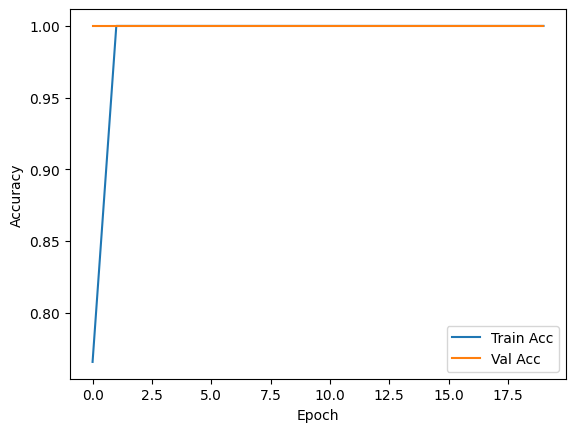

In [93]:
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [94]:
model.save('day_night_classifier_model.h5')

Assiggment

In [95]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)

In [96]:
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", X_test.shape)
print("Testing labels:", y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)


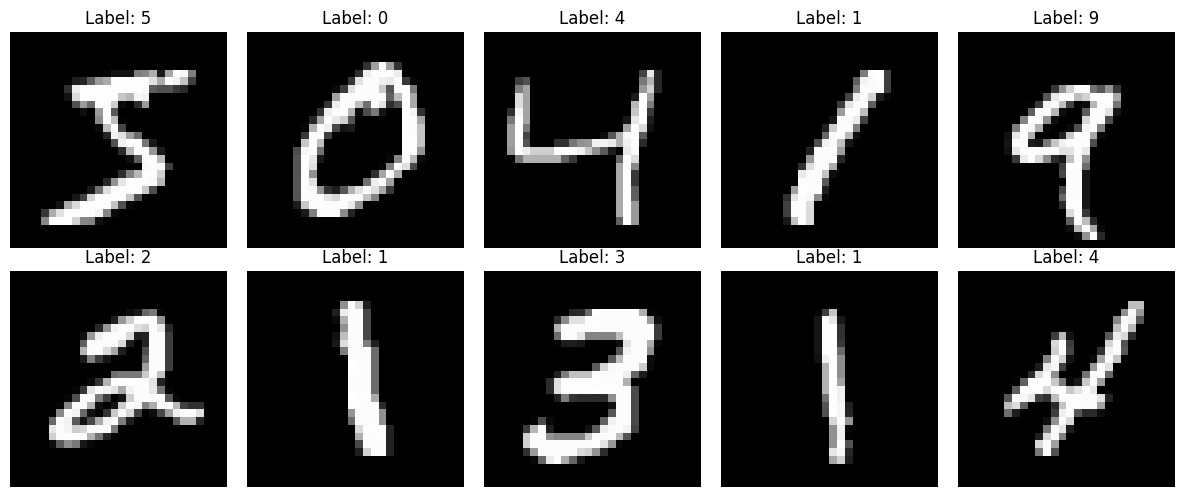

In [97]:
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [98]:
# Normalize pixel values
X_train_norm = X_train.astype('float32') / 255.0
X_test_norm = X_test.astype('float32') / 255.0

# Flatten images
X_train_flat = X_train_norm.reshape(X_train_norm.shape[0], 784)
X_test_flat = X_test_norm.reshape(X_test_norm.shape[0], 784)

print("X_train:", X_train_flat.shape)
print("X_test:", X_test_flat.shape)

X_train: (60000, 784)
X_test: (10000, 784)


In [99]:
from sklearn.model_selection import train_test_split

X_train_final, X_val, y_train_final, y_val = train_test_split(
    X_train_flat,
    y_train,
    test_size=0.1,
    random_state=42,
    stratify=y_train
)

print("Training:", X_train_final.shape)
print("Validation:", X_val.shape)

Training: (54000, 784)
Validation: (6000, 784)


In [100]:
selector = SelectKBest(score_func=f_classif, k=300)

X_train_selected = selector.fit_transform(
    X_train_final, y_train_final
)

X_val_selected = selector.transform(X_val)
X_test_selected = selector.transform(X_test_flat)

print("Original features:", X_train_final.shape[1])
print("Selected features:", X_train_selected.shape[1])

Original features: 784
Selected features: 300


/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:111: UserWarning: Features [  0   1   2   3   4   5   6   7   8   9  10  11  16  17  18  19  20  21
  22  23  24  25  26  27  28  29  30  31  32  52  53  54  55  56  57  58
  82  83  84  85 111 112 140 141 168 196 448 476 560 644 645 671 672 673
 699 700 701 727 728 729 730 754 755 756 757 758 759 780 781 782 783] are constant.
  warnings.warn("Features %s are constant." % constant_features_idx, UserWarning)
/usr/local/lib/python3.13/dist-packages/sklearn/feature_selection/_univariate_selection.py:112: RuntimeWarning: invalid value encountered in divide
  f = msb / msw


In [101]:
def create_ann(input_dim, hidden_layers, activation='relu'):

    model = models.Sequential()

    model.add(layers.Input(shape=(input_dim,)))

    for units in hidden_layers:
        model.add(
            layers.Dense(
                units=units,
                activation=activation
            )
        )

    model.add(
        layers.Dense(10, activation='softmax')
    )

    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

In [102]:
experiments = [
    {
        'name': 'ANN 1 - Baseline',
        'X_train': X_train_final,
        'X_val': X_val,
        'input_dim': 784,
        'hidden_layers': [128, 64],
        'activation': 'relu'
    },
    {
        'name': 'ANN 2 - Deeper Architecture',
        'X_train': X_train_final,
        'X_val': X_val,
        'input_dim': 784,
        'hidden_layers': [256, 128, 64],
        'activation': 'relu'
    },
    {
        'name': 'ANN 3 - Feature Selection + Tanh',
        'X_train': X_train_selected,
        'X_val': X_val_selected,
        'input_dim': 300,
        'hidden_layers': [128, 64],
        'activation': 'tanh'
    }
]

In [103]:
results = []
trained_models = {}

for exp in experiments:

    print("\nTraining:", exp['name'])

    model = create_ann(
        input_dim=exp['input_dim'],
        hidden_layers=exp['hidden_layers'],
        activation=exp['activation']
    )

    early_stop = EarlyStopping(
        monitor='val_loss',
        patience=3,
        restore_best_weights=True
    )

    history = model.fit(
        exp['X_train'],
        y_train_final,
        epochs=15,
        batch_size=128,
        validation_data=(exp['X_val'], y_val),
        callbacks=[early_stop],
        verbose=1
    )

    val_loss, val_accuracy = model.evaluate(
        exp['X_val'],
        y_val,
        verbose=0
    )

    results.append({
        'Experiment': exp['name'],
        'Activation': exp['activation'],
        'Features': exp['input_dim'],
        'Architecture': str(exp['hidden_layers']),
        'Validation Accuracy': val_accuracy,
        'Validation Loss': val_loss
    })

    trained_models[exp['name']] = {
        'model': model,
        'history': history,
        'experiment': exp
    }


Training: ANN 1 - Baseline
Epoch 1/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.8993 - loss: 0.3541 - val_accuracy: 0.9493 - val_loss: 0.1814
Epoch 2/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9595 - loss: 0.1384 - val_accuracy: 0.9607 - val_loss: 0.1395
Epoch 3/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9718 - loss: 0.0952 - val_accuracy: 0.9637 - val_loss: 0.1166
Epoch 4/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9782 - loss: 0.0728 - val_accuracy: 0.9735 - val_loss: 0.0959
Epoch 5/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9827 - loss: 0.0565 - val_accuracy: 0.9723 - val_loss: 0.0999
Epoch 6/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9853 - loss: 0.0468 - val_accuracy: 0.9745 - val_loss: 0.0882
Epoch 7/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9889 - loss: 0.0368 - val_accuracy: 0.9735 - val_loss: 0.0958
Epoch 8/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9906 - lo

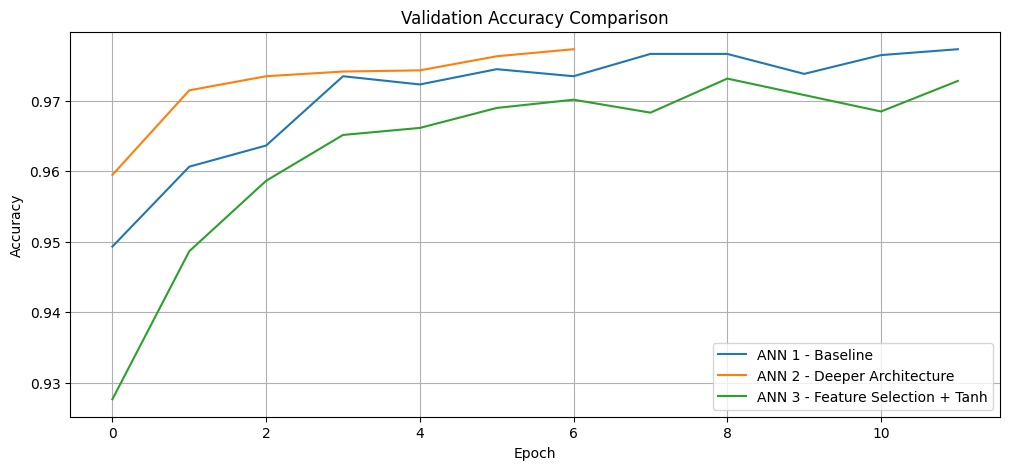

In [104]:
plt.figure(figsize=(12, 5))

for name, item in trained_models.items():
    history = item['history']

    plt.plot(
        history.history['val_accuracy'],
        label=name
    )

plt.title('Validation Accuracy Comparison')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()
plt.show()

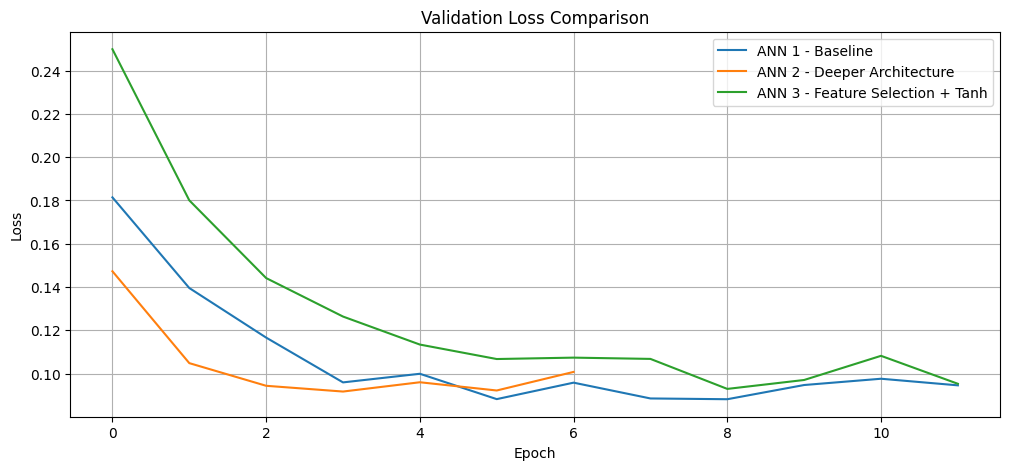

In [105]:
plt.figure(figsize=(12, 5))

for name, item in trained_models.items():
    history = item['history']

    plt.plot(
        history.history['val_loss'],
        label=name
    )

plt.title('Validation Loss Comparison')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid()
plt.show()

In [107]:
import pandas as pd

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by='Validation Accuracy',
    ascending=False
).reset_index(drop=True)

print(results_df)

                         Experiment Activation  Features    Architecture  \
0                  ANN 1 - Baseline       relu       784       [128, 64]   
1       ANN 2 - Deeper Architecture       relu       784  [256, 128, 64]   
2  ANN 3 - Feature Selection + Tanh       tanh       300       [128, 64]   

   Validation Accuracy  Validation Loss  
0             0.976667         0.088118  
1             0.974167         0.091667  
2             0.973167         0.092885  


In [108]:
best_name = results_df.iloc[0]['Experiment']

best_model = trained_models[best_name]['model']
best_exp = trained_models[best_name]['experiment']

print("Best model:", best_name)

Best model: ANN 1 - Baseline


In [109]:
if best_exp['input_dim'] == 300:
    X_test_best = X_test_selected
else:
    X_test_best = X_test_flat

In [110]:
test_loss, test_accuracy = best_model.evaluate(
    X_test_best,
    y_test,
    verbose=0
)

print("Best Model:", best_name)
print("Test Accuracy:", test_accuracy)
print("Test Loss:", test_loss)

Best Model: ANN 1 - Baseline
Test Accuracy: 0.9778000116348267
Test Loss: 0.07667620480060577


In [111]:
y_pred_prob = best_model.predict(X_test_best)

y_pred = np.argmax(y_pred_prob, axis=1)

print(classification_report(
    y_test,
    y_pred,
    digits=4
))

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step
              precision    recall  f1-score   support

           0     0.9837    0.9878    0.9857       980
           1     0.9929    0.9885    0.9907      1135
           2     0.9796    0.9777    0.9787      1032
           3     0.9695    0.9772    0.9734      1010
           4     0.9876    0.9756    0.9816       982
           5     0.9797    0.9720    0.9758       892
           6     0.9782    0.9823    0.9802       958
           7     0.9637    0.9815    0.9725      1028
           8     0.9732    0.9692    0.9712       974
           9     0.9691    0.9643    0.9667      1009

    accuracy                         0.9778     10000
   macro avg     0.9777    0.9776    0.9777     10000
weighted avg     0.9778    0.9778    0.9778     10000



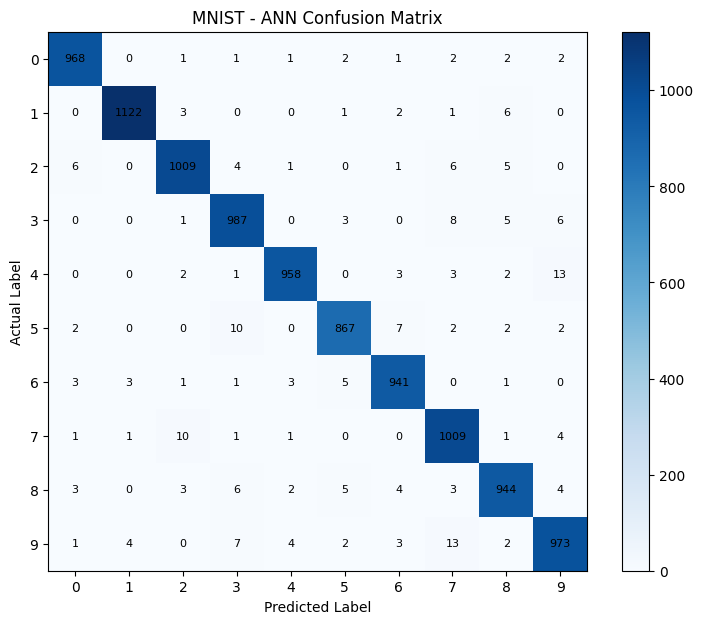

In [112]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(9, 7))

plt.imshow(cm, cmap='Blues')
plt.title('MNIST - ANN Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')

plt.xticks(range(10))
plt.yticks(range(10))

for i in range(10):
    for j in range(10):
        plt.text(
            j, i, cm[i, j],
            ha='center',
            va='center',
            fontsize=8
        )

plt.colorbar()
plt.show()

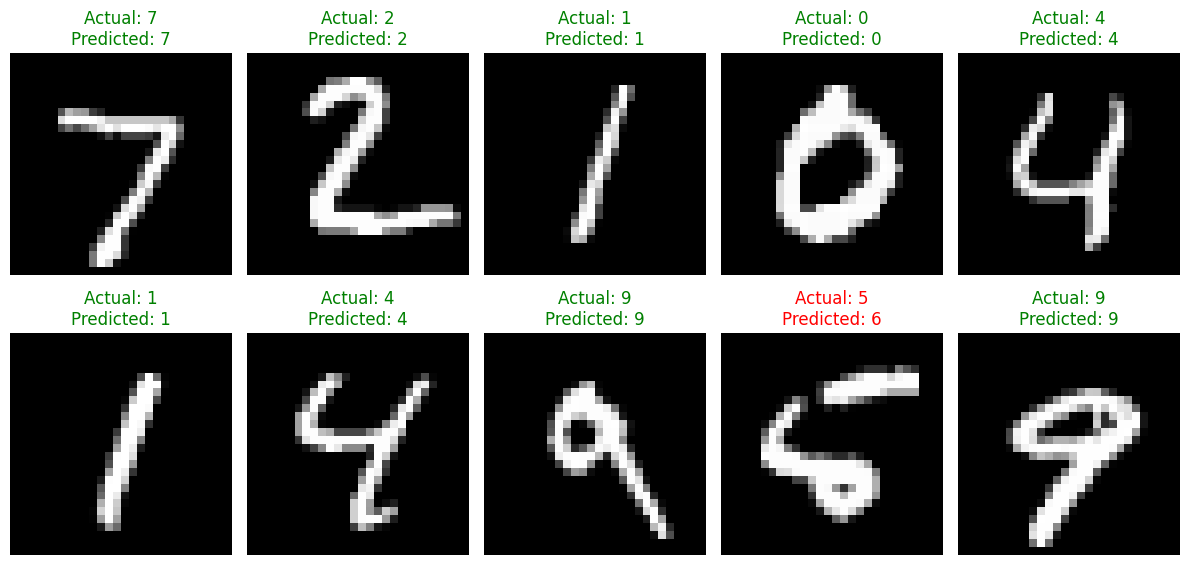

In [113]:
plt.figure(figsize=(12, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(X_test[i], cmap='gray')

    color = 'green' if y_pred[i] == y_test[i] else 'red'

    plt.title(
        f"Actual: {y_test[i]}\nPredicted: {y_pred[i]}",
        color=color
    )

    plt.axis('off')

plt.tight_layout()
plt.show()